# 1. Import libraries and clean unnecessary columns

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load original dataset
df = pd.read_csv("hospital_dataset.csv")

print("Original shape:", df.shape)

# Remove unnecessary columns
df.drop(
    columns=["random_notes", "noise_col"],
    errors="ignore",
    inplace=True
)

# Check and remove exact duplicate rows
print("Duplicate rows:", df.duplicated().sum())

df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)

print("Shape after cleaning:", df.shape)

Original shape: (30000, 20)
Duplicate rows: 0
Shape after cleaning: (30000, 18)


# 2.Handle invalid values

In [3]:
# Save a copy before making further changes
df_original = df.copy()

# Columns where negative values are invalid
non_negative_cols = [
    "Age",
    "Glucose",
    "Blood Pressure",
    "BMI",
    "Oxygen Saturation",
    "LengthOfStay",
    "Cholesterol",
    "Triglycerides",
    "HbA1c",
    "Physical Activity",
    "Diet Score",
    "Stress Level",
    "Sleep Hours"
]

# Replace negative values with NaN
for col in non_negative_cols:
    if col in df.columns:
        df.loc[df[col] < 0, col] = np.nan

# Oxygen saturation above 100% is invalid
if "Oxygen Saturation" in df.columns:
    df.loc[df["Oxygen Saturation"] > 100,
           "Oxygen Saturation"] = np.nan

print(df.isnull().sum())

Age                  4500
Gender               4500
Medical Condition    4500
Glucose              4500
Blood Pressure       4500
BMI                     0
Oxygen Saturation    1793
LengthOfStay            0
Cholesterol             0
Triglycerides           4
HbA1c                   0
Smoking                 0
Alcohol                 0
Physical Activity     302
Diet Score            105
Family History          0
Stress Level           67
Sleep Hours             0
dtype: int64


# 3. Standardize categorical values

In [4]:
# Clean whitespace in categorical columns
categorical_cols = df.select_dtypes(include="object").columns

for col in categorical_cols:
    df[col] = df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

# Handle missing categorical values
for col in ["Gender", "Medical Condition"]:
    if col in df.columns:
        df[col] = df[col].fillna("Unknown")

# Normalize Gender labels
if "Gender" in df.columns:
    df["Gender"] = df["Gender"].replace({
        "male": "Male",
        "MALE": "Male",
        "female": "Female",
        "FEMALE": "Female"
    })

# Inspect categories
for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))


Gender:
Gender
Female     12865
Male       12635
Unknown     4500
Name: count, dtype: int64

Medical Condition:
Medical Condition
Hypertension    7120
Diabetes        6417
Unknown         4500
Obesity         3857
Healthy         3039
Asthma          2037
Arthritis       1796
Cancer          1234
Name: count, dtype: int64


# 4.Creating KNN Imputation function

In [5]:
def knn_impute_column(df, target_col, k=5):
    df = df.copy()

    # Rows with known and missing target values
    known_mask = df[target_col].notna()
    missing_mask = df[target_col].isna()

    if not missing_mask.any():
        return df

    # Use other numerical columns as predictors
    numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

    # Exclude all columns being imputed from the predictors
    target_cols = [
        "Age",
        "Glucose",
        "Blood Pressure"
    ]

    feature_cols = [
        col for col in numeric_cols
        if col not in target_cols
    ]

    if len(feature_cols) == 0:
        raise ValueError("No numerical predictor columns available.")

    # Separate known and missing target records
    X_known = df.loc[known_mask, feature_cols].copy()
    X_missing = df.loc[missing_mask, feature_cols].copy()

    y_known = df.loc[known_mask, target_col].to_numpy(dtype=float)

    # Calculate medians from known target rows
    medians = X_known.median().fillna(0)

    X_known = X_known.fillna(medians)
    X_missing = X_missing.fillna(medians)

    # Standardize features using training rows only
    means = X_known.mean()
    stds = X_known.std(ddof=0).replace(0, 1).fillna(1)

    X_known = ((X_known - means) / stds).to_numpy(dtype=float)
    X_missing = ((X_missing - means) / stds).to_numpy(dtype=float)

    # Impute each missing record
    for i, row in enumerate(X_missing):

        # Euclidean distance
        distances = np.sqrt(
            np.sum((X_known - row) ** 2, axis=1)
        )

        # Select k nearest neighbours
        k_actual = min(k, len(distances))
        nearest_idx = np.argsort(distances)[:k_actual]

        nearest_distances = distances[nearest_idx]
        nearest_values = y_known[nearest_idx]

        # Exact matches: average values of zero-distance neighbours
        zero_mask = nearest_distances == 0

        if zero_mask.any():
            prediction = nearest_values[zero_mask].mean()
        else:
            # Inverse-distance weighted average
            weights = 1 / nearest_distances
            prediction = np.sum(
                weights * nearest_values
            ) / np.sum(weights)

        # Assign prediction to original missing row
        row_index = df.index[missing_mask][i]
        df.loc[row_index, target_col] = prediction

    return df

# 5.Apply KNN to your three columns

In [6]:
# Keep a copy of the dataset before imputation
df_before_knn = df.copy()

# Apply our custom KNN function
for col in ["Age", "Glucose", "Blood Pressure"]:
    if col in df.columns:
        df = knn_impute_column(df, target_col=col, k=5)

# Check results
print("Missing values after KNN:")

for col in ["Age", "Glucose", "Blood Pressure"]:
    if col in df.columns:
        print(col, ":", df[col].isnull().sum())

Missing values after KNN:
Age : 0
Glucose : 0
Blood Pressure : 0


# 6.Validate the results

In [7]:
# Check missing values across the entire dataset
print("Missing values by column:")
print(df.isnull().sum())

print("\nTotal missing cells:", df.isnull().sum().sum())

# Check duplicates
print("\nDuplicate rows:", df.duplicated().sum())

# Check data types
print("\nData types:")
print(df.dtypes)

# Summary statistics
print("\nNumerical summary:")
print(df.describe().T)

Missing values by column:
Age                     0
Gender                  0
Medical Condition       0
Glucose                 0
Blood Pressure          0
BMI                     0
Oxygen Saturation    1793
LengthOfStay            0
Cholesterol             0
Triglycerides           4
HbA1c                   0
Smoking                 0
Alcohol                 0
Physical Activity     302
Diet Score            105
Family History          0
Stress Level           67
Sleep Hours             0
dtype: int64

Total missing cells: 2271

Duplicate rows: 0

Data types:
Age                  float64
Gender                object
Medical Condition     object
Glucose              float64
Blood Pressure       float64
BMI                  float64
Oxygen Saturation    float64
LengthOfStay         float64
Cholesterol          float64
Triglycerides        float64
HbA1c                float64
Smoking                int64
Alcohol                int64
Physical Activity    float64
Diet Score           float64

# 7.Compare distributions before and after

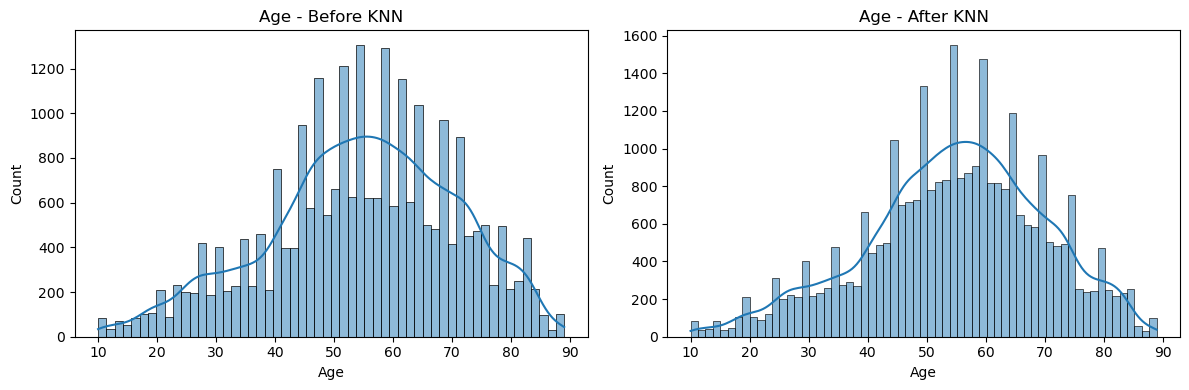

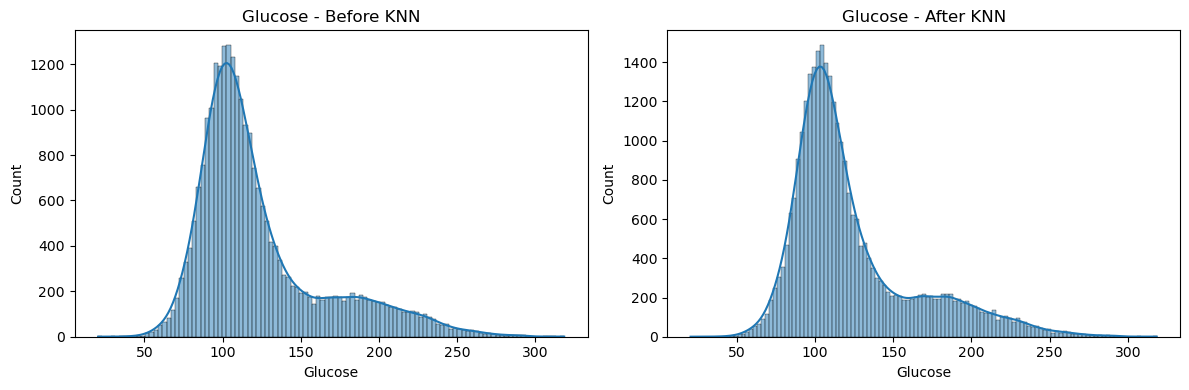

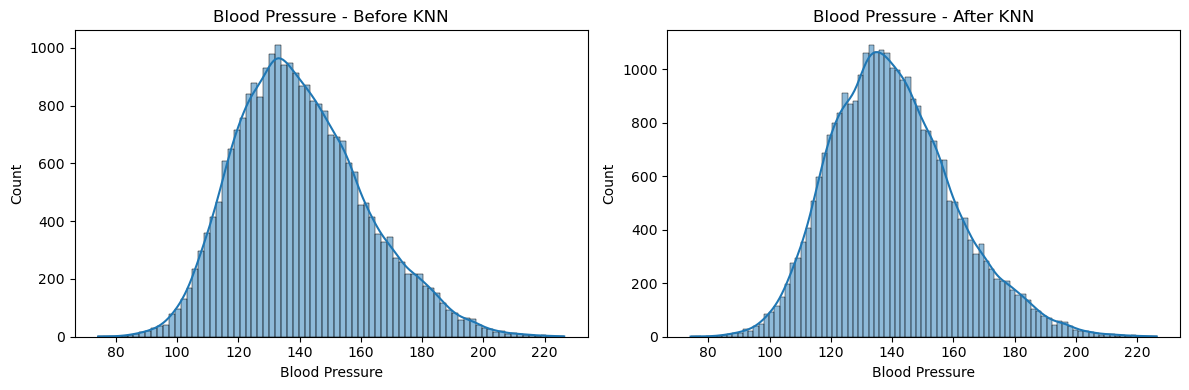

In [8]:
for col in ["Age", "Glucose", "Blood Pressure"]:

    if col not in df.columns:
        continue

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Original observed values
    sns.histplot(
        df_before_knn[col].dropna(),
        kde=True,
        ax=axes[0]
    )
    axes[0].set_title(f"{col} - Before KNN")

    # Values after imputation
    sns.histplot(
        df[col].dropna(),
        kde=True,
        ax=axes[1]
    )
    axes[1].set_title(f"{col} - After KNN")

    plt.tight_layout()
    plt.show()

# 8.Final quality checks

In [10]:
# Check logical ranges
if "Age" in df.columns:
    print("Age outside 0-120:",
          ((df["Age"] < 0) | (df["Age"] > 120)).sum())

if "Oxygen Saturation" in df.columns:
    print("Oxygen saturation above 100:",
          (df["Oxygen Saturation"] > 100).sum())

if "Sleep Hours" in df.columns:
    print("Sleep hours above 24:",
          (df["Sleep Hours"] > 24).sum())


Age outside 0-120: 0
Oxygen saturation above 100: 0
Sleep hours above 24: 0


In [ ]:
#